# Predictive Modeling Using Machine Learning
**Task 2 – Supervised Learning & Model Evaluation**

**Goal:** Build models that predict whether a tumour is *malignant* or *benign* from medical measurements.

**Plan**
1. Load and explore the data
2. Split into train / test sets
3. Train 3 algorithms: Logistic Regression (linear model for classification), Decision Tree, Random Forest
4. Evaluate with accuracy, confusion matrices and ROC curves
5. Compare and conclude

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score, classification_report)

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target          # target: 0 = malignant, 1 = benign
print("Shape:", X.shape)
print("Class counts:\n", y.map({0: 'malignant', 1: 'benign'}).value_counts())
X.head()

Shape: (569, 30)
Class counts:
 target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


The dataset has **569 samples** and **30 numeric features** (radius, texture, perimeter, area, etc. of cell nuclei). It is a clean, real-world binary classification problem.

## 2. Train / test split
We keep 20% of the data hidden for testing so we can measure how the model does on **unseen** data. `stratify=y` keeps the class ratio equal in both sets.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (455, 30)  Test: (114, 30)


## 3. Train the models

In [3]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree":       DecisionTreeClassifier(max_depth=4, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: Decision Tree


Trained: Random Forest


- **Logistic Regression** – linear model; features are scaled first so no feature dominates.
- **Decision Tree** – learns if/else rules; depth limited to 4 to avoid overfitting.
- **Random Forest** – 200 trees voting together; usually more accurate and stable than one tree.

## 4. Evaluate: accuracy and other metrics

In [4]:
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Train Acc": accuracy_score(y_train, model.predict(X_train)),
        "Test Acc": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })
results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
Model,,,,,,
Logistic Regression,0.989,0.982,0.986,0.986,0.986,0.995
Decision Tree,0.987,0.939,0.958,0.944,0.951,0.934
Random Forest,1.000,0.956,0.959,0.972,0.966,0.993


## 5. Confusion matrices

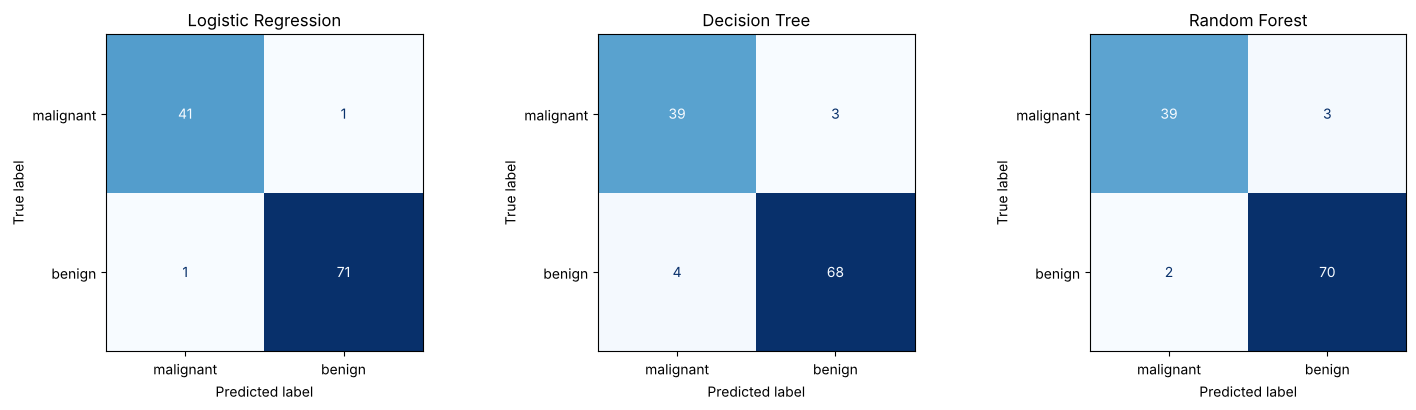

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test, display_labels=["malignant", "benign"],
        cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()

**How to read it:** rows = actual class, columns = predicted class. The diagonal is correct predictions. The off-diagonal cells are mistakes. A *malignant* tumour predicted as *benign* (false negative) is the most dangerous error in a medical setting.

## 6. ROC curves

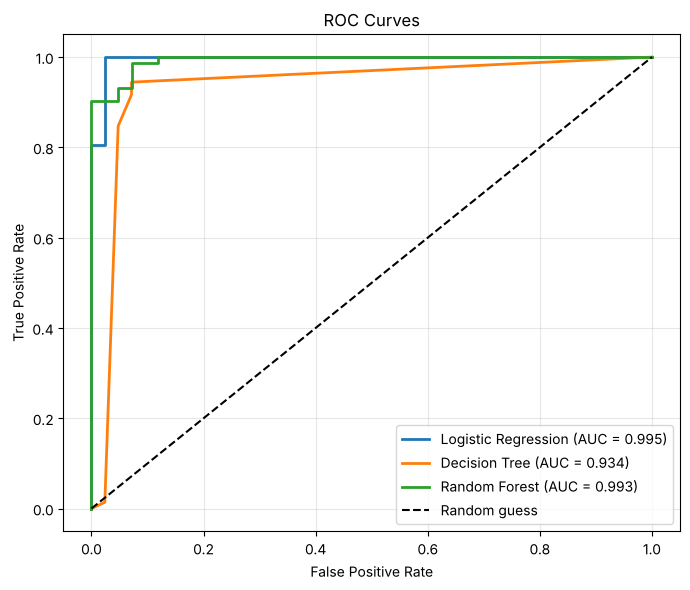

In [6]:
plt.figure(figsize=(7, 6))
for name, model in models.items():
    proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=150)
plt.show()

The closer a curve hugs the top-left corner (and the higher the AUC), the better the model separates the two classes. The dashed line is a coin flip (AUC = 0.5).

## 7. Which features matter? (Random Forest)

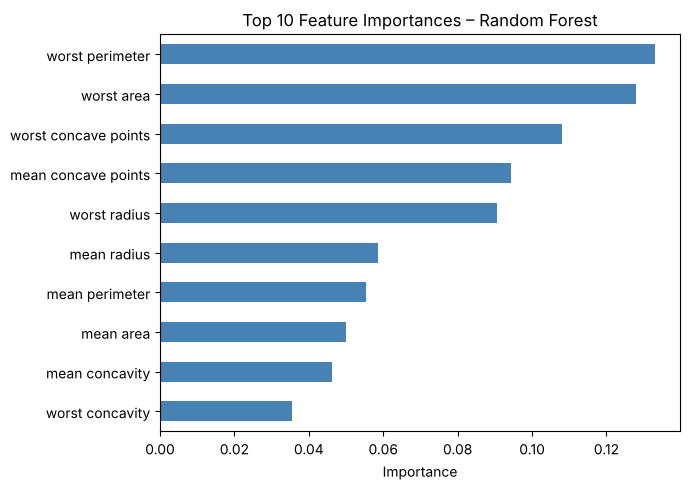

In [7]:
imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values()
imp.tail(10).plot(kind="barh", figsize=(7, 5), color="steelblue")
plt.title("Top 10 Feature Importances – Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

## 8. Detailed report for the best model

In [8]:
best = results["Test Acc"].idxmax()
print("Best model by test accuracy:", best)
print(classification_report(y_test, models[best].predict(X_test),
                            target_names=["malignant", "benign"]))

Best model by test accuracy: Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## 9. Conclusion
- All three models learned to predict tumour type well on unseen data (see the results table for exact numbers).
- **Logistic Regression** and **Random Forest** are typically the strongest here; the single **Decision Tree** is the most interpretable but is more prone to overfitting (check the gap between its train and test accuracy).
- Confusion matrices show *where* each model errs, and ROC curves/AUC show how well each separates the classes across all thresholds, which is more informative than accuracy alone.
- **Takeaway:** this task demonstrated the full supervised-learning workflow: split data, train multiple models, evaluate on held-out data, and compare using visual metrics.

*Possible improvements:* cross-validation, hyperparameter tuning (GridSearchCV), and testing on other datasets.